In [101]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [102]:
df = pd.read_csv("car_price_predication.csv", usecols=["name","year","selling_price","km_driven","fuel","seller_type","transmission","owner"])
pd.set_option("display.max_columns",None)
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti,2014,450000,145500,Diesel,Individual,Manual,First Owner
1,Hyundai,2010,225000,127000,Diesel,Individual,Manual,First Owner
2,Hyundai,2017,440000,45000,Petrol,Individual,Manual,First Owner
3,Toyota,2011,350000,90000,Diesel,Individual,Manual,First Owner
4,Ford,2013,200000,169000,Diesel,Individual,Manual,First Owner


In [103]:
df.columns = df.columns.str.strip()

In [104]:
df.shape

(2095, 8)

In [105]:
df.columns.tolist()

['name',
 'year',
 'selling_price',
 'km_driven',
 'fuel',
 'seller_type',
 'transmission',
 'owner']

In [106]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2095 entries, 0 to 2094
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           2095 non-null   object
 1   year           2095 non-null   int64 
 2   selling_price  2095 non-null   int64 
 3   km_driven      2095 non-null   int64 
 4   fuel           2095 non-null   object
 5   seller_type    2095 non-null   object
 6   transmission   2095 non-null   object
 7   owner          2095 non-null   object
dtypes: int64(3), object(5)
memory usage: 131.1+ KB


In [107]:
df.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0


In [108]:
df.duplicated().sum()

np.int64(15)

In [109]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,2095,10,Maruti,921,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,2095.0,NaN,NaN,NaN,2014.052506,3.273451,2000.0,2012.0,2014.0,2017.0,2020.0
selling_price,2095.0,NaN,NaN,NaN,427279.879236,232669.849553,45957.0,250000.0,390000.0,555500.0,1594000.0
km_driven,2095.0,NaN,NaN,NaN,67413.593795,41580.846333,1000.0,35000.0,60000.0,90000.0,270000.0
fuel,2095,4,Diesel,1075,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,2095,3,Individual,1919,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,2095,2,Manual,1996,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,2095,5,First Owner,1325,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [110]:
df.drop_duplicates()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti,2014,450000,145500,Diesel,Individual,Manual,First Owner
1,Hyundai,2010,225000,127000,Diesel,Individual,Manual,First Owner
2,Hyundai,2017,440000,45000,Petrol,Individual,Manual,First Owner
3,Toyota,2011,350000,90000,Diesel,Individual,Manual,First Owner
4,Ford,2013,200000,169000,Diesel,Individual,Manual,First Owner
...,...,...,...,...,...,...,...,...
2090,Maruti,2017,425000,12000,Petrol,Individual,Manual,First Owner
2091,Toyota,2014,425000,50000,Diesel,Individual,Manual,First Owner
2092,Maruti,2011,200000,73000,Petrol,Individual,Manual,First Owner
2093,Maruti,2017,360000,80000,Petrol,Individual,Manual,First Owner


In [111]:
# Standardize spaces and categorical values.
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )
    df[col] = df[col].replace("", np.nan)

# Standardize capitalization for common categorical columns.
for col in ["Fuel_Type", "Seller_Type", "Transmission"]:
    if col in df.columns:
        df[col] = df[col].apply(
            lambda x: x.title() if isinstance(x, str) else x
        )


In [112]:
# Convert numeric columns.
for col in [
    "sear", "selling_price", "Present_Price",
    "Km_Driven", "Owner"
]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

if "selling_price" not in df.columns:
    raise ValueError("Dataset must contain a Selling_Price column.")

In [113]:
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [114]:
# Remove rows without a valid target or with negative prices.
df = df.dropna(subset=["selling_price"]).copy()
df = df[df["selling_price"] >= 0].copy()

print("\nShape after cleaning:", df.shape)
print(df.isnull().sum())



Shape after cleaning: (2095, 8)
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64


In [115]:
# STEP 5: FEATURE ENGINEERING
# Calculate the age of each car.
if "year" in df.columns:
    current_year = pd.Timestamp.today().year
    df["Car_Age"] = current_year - df["year"]

    invalid_years = (
        (df["year"] < 1900) |
        (df["year"] > current_year)
    )
    df.loc[invalid_years, "Car_Age"] = np.nan

In [116]:
# Extract brand from the car name.
if "Car_Name" in df.columns:
    df["Brand"] = (
        df["Car_Name"]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .str.split()
        .str[0]
        .str.title()
    )

    df.drop(columns=["Car_Name", "Year"], inplace=True)

print("\nDataset after feature engineering:")
print(df.head())
print(df.columns.tolist())


Dataset after feature engineering:
      name  year  selling_price  km_driven    fuel seller_type transmission  \
0   Maruti  2014         450000     145500  Diesel  Individual       Manual   
1  Hyundai  2010         225000     127000  Diesel  Individual       Manual   
2  Hyundai  2017         440000      45000  Petrol  Individual       Manual   
3   Toyota  2011         350000      90000  Diesel  Individual       Manual   
4     Ford  2013         200000     169000  Diesel  Individual       Manual   

         owner  Car_Age  
0  First Owner     12.0  
1  First Owner     16.0  
2  First Owner      9.0  
3  First Owner     15.0  
4  First Owner     13.0  
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'Car_Age']


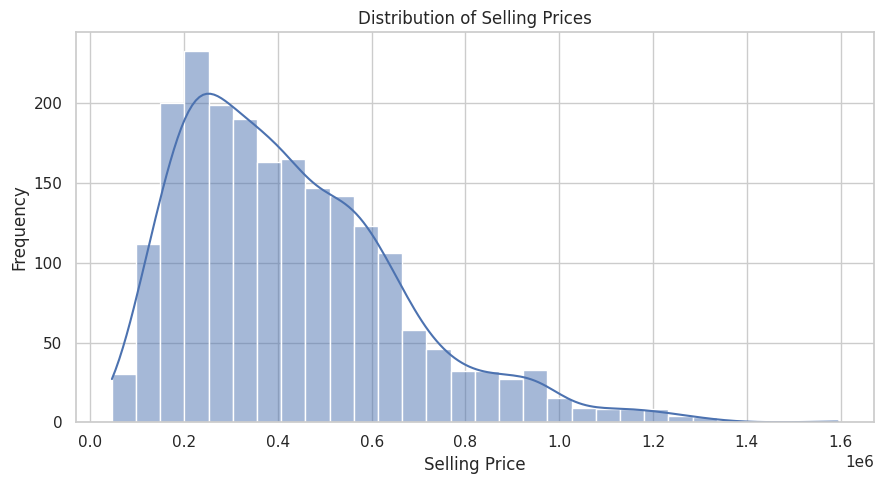

In [117]:
# STEP 6: EXPLORATORY DATA ANALYSIS

# 6.1 Distribution of selling prices.
plt.figure(figsize=(9, 5))
sns.histplot(df["selling_price"], kde=True, bins=30)
plt.title("Distribution of Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


In [118]:
# 6.2 Selling price versus fuel type.
if "Fuel_Type" in df.columns:
    plt.figure(figsize=(9, 5))
    sns.boxplot(data=df, x="Fuel_Type", y="Selling_Price")
    plt.title("Selling Price by Fuel Type")
    plt.tight_layout()
    plt.show()

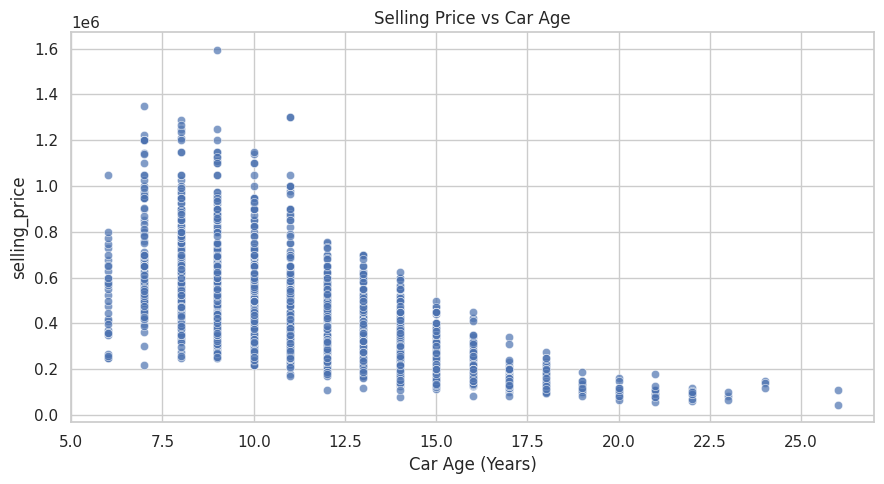

In [119]:
# 6.3 Selling price versus car age.
if "Car_Age" in df.columns:
    plt.figure(figsize=(9, 5))
    sns.scatterplot(
        data=df,
        x="Car_Age",
        y="selling_price",
        alpha=0.7
    )
    plt.title("Selling Price vs Car Age")
    plt.xlabel("Car Age (Years)")
    plt.tight_layout()
    plt.show()

In [120]:
# 6.4 Selling price versus transmission.
if "Transmission" in df.columns:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x="Transmission", y="Selling_Price")
    plt.title("Selling Price by Transmission")
    plt.tight_layout()
    plt.show()

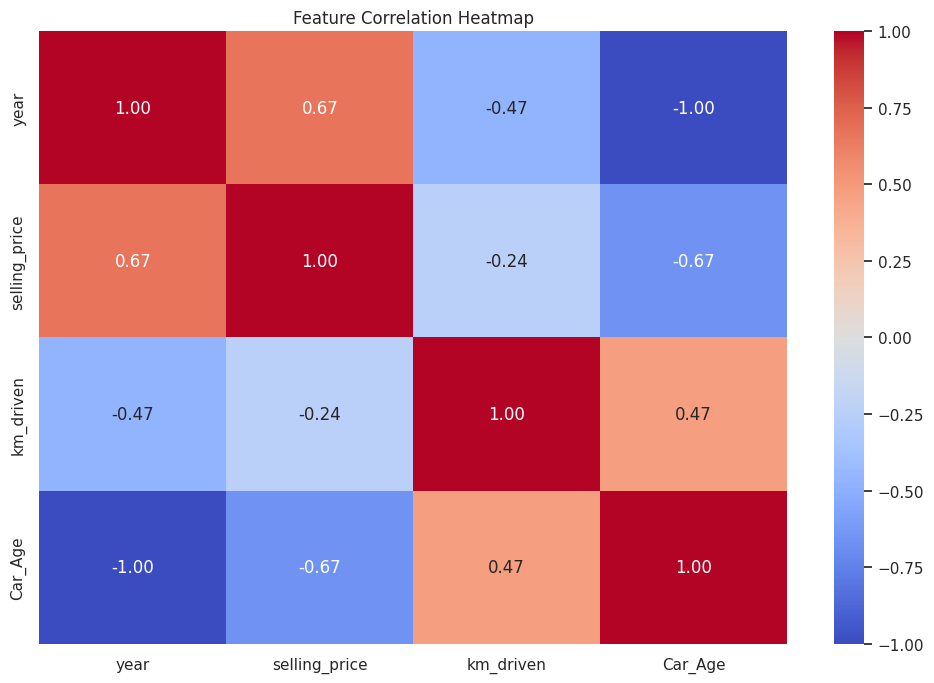


Correlation with Selling Price:
selling_price    1.000000
year             0.669213
km_driven       -0.239156
Car_Age         -0.669213
Name: selling_price, dtype: float64


In [121]:
# STEP 7: CORRELATION HEATMAP
numeric_df = df.select_dtypes(include=[np.number])

plt.figure(figsize=(10, 7))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

print("\nCorrelation with Selling Price:")
print(
    numeric_df.corr()["selling_price"]
    .sort_values(ascending=False)
)


In [122]:
# STEP 8: INPUT FEATURES AND TARGET
X = df.drop(columns=["selling_price"]).copy()
y = df["selling_price"].copy()

In [123]:
# Remove columns that contain no usable values.
X.dropna(axis=1, how="all", inplace=True)

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nInput features:", X.columns.tolist())
print("Target feature: Selling_Price")
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)



Input features: ['name', 'year', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'Car_Age']
Target feature: Selling_Price
Numeric features: ['year', 'km_driven', 'Car_Age']
Categorical features: ['name', 'fuel', 'seller_type', 'transmission', 'owner']


In [124]:
# STEP 9: TRAIN/TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 1676
Testing samples: 419


In [125]:
# STEP 10: PREPROCESSING
# Fill missing numeric values and scale numeric features.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [126]:
# Fill missing categories and apply one-hot encoding.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []

if numeric_features:
    transformers.append(
        ("numeric", numeric_transformer, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("categorical", categorical_transformer, categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)


In [127]:
# STEP 11: TRAIN THREE REGRESSION MODELS
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=RANDOM_STATE
    )
}

trained_models = {}
results = []

for name, model in models.items():
    print(f"\nTraining {name}...")

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R2 Score: {r2:.4f}")



Training Linear Regression...
MAE: 94720.1411
RMSE: 125186.2804
R2 Score: 0.6685

Training Random Forest...
MAE: 81372.1108
RMSE: 112311.7585
R2 Score: 0.7332

Training Gradient Boosting...
MAE: 77595.0833
RMSE: 103587.2383
R2 Score: 0.7730


In [128]:
# STEP 12: COMPARE MODELS
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

print("\n" + "=" * 60)
print("MODEL COMPARISON")
print("=" * 60)
print(results_df.to_string(index=False))


MODEL COMPARISON
            Model          MAE          RMSE  R2 Score
Gradient Boosting 77595.083281 103587.238289  0.772999
    Random Forest 81372.110755 112311.758495  0.733151
Linear Regression 94720.141147 125186.280374  0.668466


In [129]:
# Select the model with the lowest test RMSE.
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("\nBest model based on test RMSE:", best_model_name)


Best model based on test RMSE: Gradient Boosting


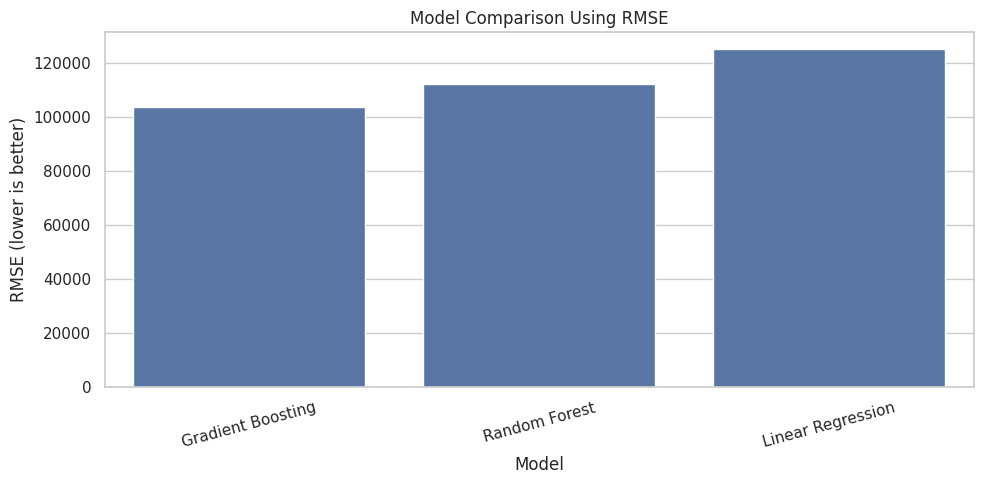

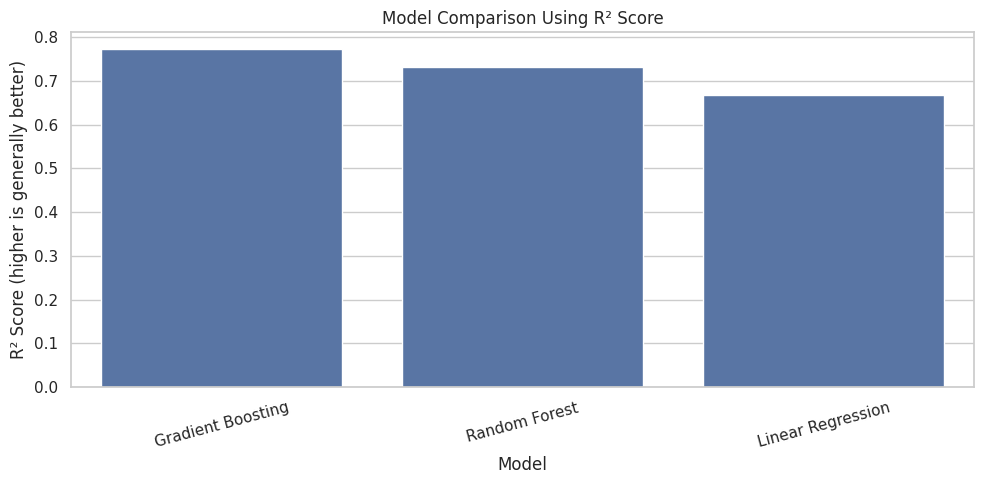

In [130]:
# STEP 13: VISUALIZE MODEL PERFORMANCE
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="RMSE")
plt.title("Model Comparison Using RMSE")
plt.ylabel("RMSE (lower is better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="R2 Score")
plt.title("Model Comparison Using R² Score")
plt.ylabel("R² Score (higher is generally better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

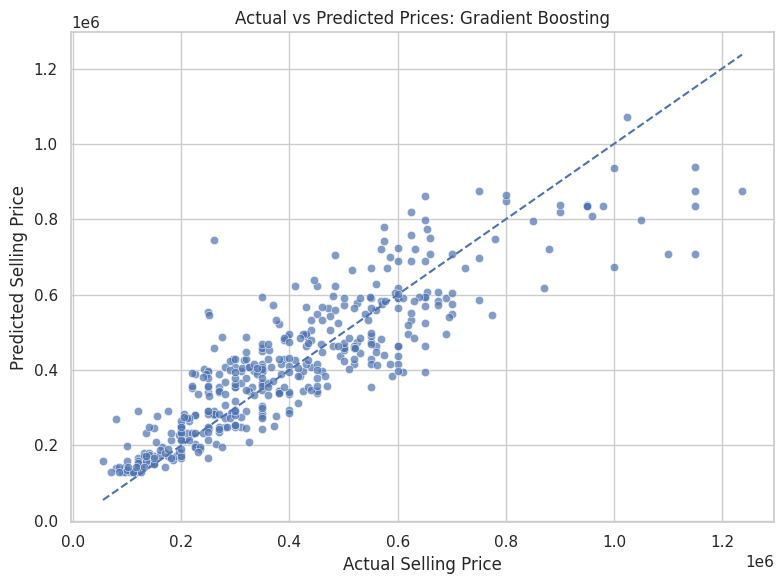

In [131]:
# STEP 14: ACTUAL VS PREDICTED PRICES
best_predictions = best_model.predict(X_test)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=best_predictions, alpha=0.7)

min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title(f"Actual vs Predicted Prices: {best_model_name}")
plt.tight_layout()
plt.show()

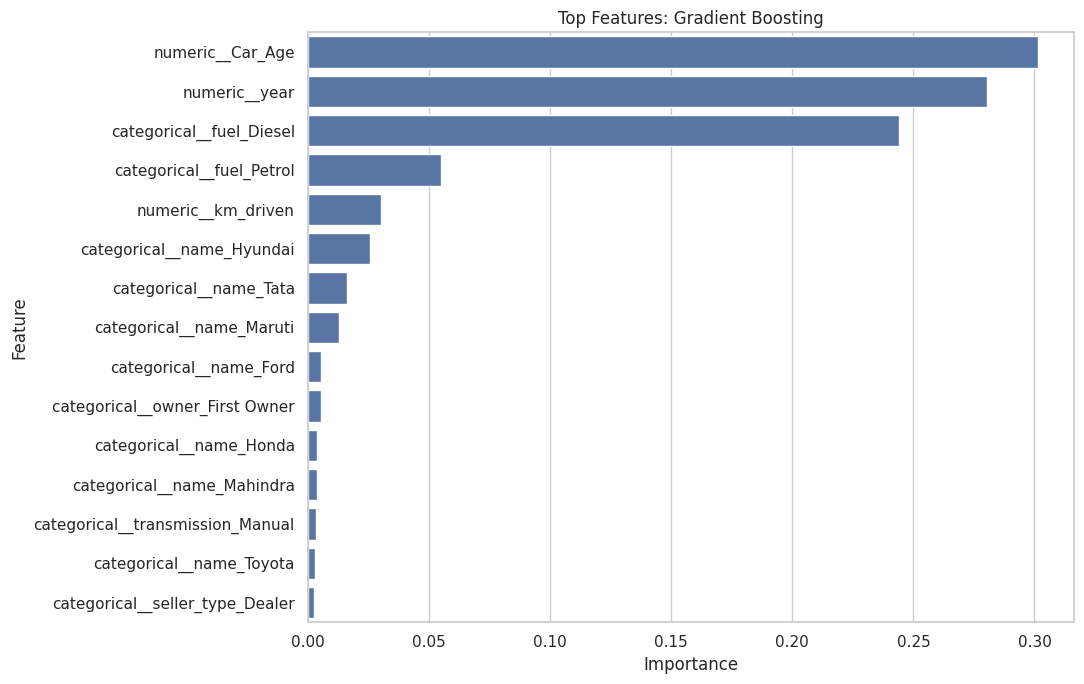


Top important features:
                         Feature  Importance
                numeric__Car_Age    0.301251
                   numeric__year    0.280329
        categorical__fuel_Diesel    0.243978
        categorical__fuel_Petrol    0.054816
              numeric__km_driven    0.030339
       categorical__name_Hyundai    0.025476
          categorical__name_Tata    0.016307
        categorical__name_Maruti    0.012710
          categorical__name_Ford    0.005377
  categorical__owner_First Owner    0.005169
         categorical__name_Honda    0.003814
      categorical__name_Mahindra    0.003626
categorical__transmission_Manual    0.003236
        categorical__name_Toyota    0.002921
 categorical__seller_type_Dealer    0.002439


In [132]:
# STEP 15: FEATURE IMPORTANCE
# Random Forest and Gradient Boosting provide feature_importances_.
# For Linear Regression, use absolute coefficient magnitudes.

fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_estimator = best_model.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

if hasattr(fitted_estimator, "feature_importances_"):
    importance_values = fitted_estimator.feature_importances_

elif hasattr(fitted_estimator, "coef_"):
    importance_values = np.abs(
        np.asarray(fitted_estimator.coef_).ravel()
    )

else:
    importance_values = None

if importance_values is not None:
    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance_values
    })

    importance_df = importance_df.sort_values(
        by="Importance",
        ascending=False
    ).head(15)

    plt.figure(figsize=(11, 7))
    sns.barplot(
        data=importance_df,
        x="Importance",
        y="Feature"
    )
    plt.title(f"Top Features: {best_model_name}")
    plt.tight_layout()
    plt.show()

    print("\nTop important features:")
    print(importance_df.to_string(index=False))


In [133]:
# STEP 16: DISPLAY ACTUAL AND PREDICTED PRICES
comparison_df = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": best_predictions
})

comparison_df["Absolute Error"] = abs(
    comparison_df["Actual Price"] -
    comparison_df["Predicted Price"]
)

print("\nActual vs Predicted Prices (first 10 rows):")
print(comparison_df.head(10).round(3))


Actual vs Predicted Prices (first 10 rows):
   Actual Price  Predicted Price  Absolute Error
0       1050000       798816.158      251183.842
1        600000       616323.219       16323.219
2        395000       486685.427       91685.427
3        493000       437294.728       55705.272
4        185000       160414.329       24585.671
5        310000       364519.840       54519.840
6        100000       198256.590       98256.590
7        225000       281588.807       56588.807
8        850000       794522.337       55477.663
9        252000       246850.532        5149.468


In [134]:
# STEP 17: PREDICT A PRICE FOR A NEW CAR
# This example uses the first row of the test dataset.
# It predicts the price of an existing test example.
sample_car = X_test.iloc[[0]]
actual_price = y_test.iloc[0]
predicted_price = best_model.predict(sample_car)[0]

print("\n" + "=" * 60)
print("SAMPLE CAR PRICE PREDICTION")
print("=" * 60)
print("Input car details:")
print(sample_car.to_string(index=False))
print(f"\nActual selling price: {actual_price:.2f}")
print(f"Predicted selling price: {predicted_price:.2f}")


SAMPLE CAR PRICE PREDICTION
Input car details:
   name  year  km_driven   fuel seller_type transmission       owner  Car_Age
Hyundai  2017      60000 Diesel  Individual       Manual First Owner      9.0

Actual selling price: 1050000.00
Predicted selling price: 798816.16


In [135]:
# STEP 18: FINAL SUMMARY
print("\n" + "=" * 60)
print("PROJECT COMPLETED SUCCESSFULLY")
print("=" * 60)
print("Dataset rows used:", len(df))
print("Number of input features:", X.shape[1])
print("Models trained:", len(trained_models))
print("Best model:", best_model_name)

best_result = results_df.iloc[0]
print(f"Best model MAE: {best_result['MAE']:.4f}")
print(f"Best model RMSE: {best_result['RMSE']:.4f}")
print(f"Best model R2 Score: {best_result['R2 Score']:.4f}")


PROJECT COMPLETED SUCCESSFULLY
Dataset rows used: 2095
Number of input features: 8
Models trained: 3
Best model: Gradient Boosting
Best model MAE: 77595.0833
Best model RMSE: 103587.2383
Best model R2 Score: 0.7730
